# International metropolitan areas from city data

This notebook implements two Python APIs (classes, not web services): **DataCleaningAPI → DataProcessingAPI → CSV**. All implementation lives here.

## Steps
1. Load `msa.csv` and audit missing values, invalid coordinates, population, and duplicates.
2. Explore population, geography, country coverage and noisy traditional labels.
3. Transform coordinates into radians for spherical distance and Cartesian coordinates for K-means; normalize log population only for supervised experiments.
4. Compare K-means (elbow + silhouette), DBSCAN (distance/density sensitivity), and optional SVM classification.
5. Create population-aware metro anchors, assign nearby cities with a strict distance cap, and retain each remaining city as its own non-metro entity.
6. Compare against noisy US labels, inspect international outputs and export the required seven columns.

**Scope:** these are proposed geographic population catchments, not official commuting-based MSAs. City population is not employment, coordinates are not boundaries, and this dataset cannot establish commuting integration. Traditional labels are evaluation data only. International thresholds need local validation.


In [1]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from IPython.display import display
SEED = 42
EARTH_KM = 6371.0088
INPUT = Path('msa.csv')
OUTPUT = Path('msa_output.csv')
assert INPUT.exists(), 'Put msa.csv beside this notebook, then run all cells.'
print('Python:', platform.python_version())
import sklearn
print('scikit-learn:', sklearn.__version__)


Python: 3.9.6
scikit-learn: 1.6.1


## 1. Cleaning API
Preserve every input row and its original city/state/traditional label in the deliverable. Canonical text is used internally. Invalid coordinates or missing country exclude a row from geographic modeling and produce a distinct review label. Unknown population remains unknown: such cities can join a nearby anchor but cannot seed one. Exact duplicate observations are modeled once and mapped back; conflicting records remain separate and are reported. No population clipping or invented coordinate imputation.

In [2]:
class DataCleaningAPI:
    required = ['city', 'state', 'country', 'latitude', 'longitude', 'population', 'msa']
    def clean(self, source):
        raw = pd.read_csv(source)
        missing = set(self.required) - set(raw.columns)
        if missing: raise ValueError(f'Missing columns: {sorted(missing)}')
        d = raw[self.required].copy()
        d['row_id'] = np.arange(len(d))
        for col in ['city', 'state', 'country']:
            d[col + '_key'] = d[col].fillna('').astype(str).str.strip().str.casefold()
        for col in ['latitude', 'longitude', 'population']:
            d[col] = pd.to_numeric(d[col], errors='coerce')
        bad_pop = ~np.isfinite(d.population) | (d.population < 0)
        d.loc[bad_pop, 'population'] = np.nan
        d['geo_valid'] = (d.latitude.between(-90, 90) & d.longitude.between(-180, 180)
                          & d.country_key.ne('') & d.city_key.ne(''))
        identity = ['city_key', 'state_key', 'country_key', 'latitude', 'longitude', 'population']
        d['model_id'] = d.groupby(identity, dropna=False, sort=False).ngroup()
        self.audit = pd.Series({
            'input_rows': len(d), 'invalid_geography_or_identity': int((~d.geo_valid).sum()),
            'unknown_or_invalid_population': int(d.population.isna().sum()),
            'duplicate_observations': int(d.duplicated(identity).sum()),
            'repeated_city_state_country': int(d.duplicated(['city_key','state_key','country_key']).sum()),
            'missing_traditional_labels': int(d.msa.isna().sum())})
        self.rows = d
        return d.drop_duplicates('model_id').reset_index(drop=True)
    @staticmethod
    def transform(d):
        radians = np.radians(d[['latitude','longitude']].to_numpy(float))
        lat, lon = radians.T
        xyz = EARTH_KM * np.column_stack([np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)])
        return {'radians': radians, 'xyz_km': xyz,
                'log_population': np.log1p(d.population.to_numpy(float))}

cleaner = DataCleaningAPI()
cities = cleaner.clean(INPUT)
display(cleaner.audit.to_frame('count'))
display(cities.head())


,count
input_rows,25410
invalid_geography_or_identity,0
unknown_or_invalid_population,0
duplicate_observations,0
repeated_city_state_country,0
missing_traditional_labels,18383


,city,state,country,latitude,longitude,population,msa,row_id,city_key,state_key,country_key,geo_valid,model_id
0,mahopac,new york,united states,41.37232,-73.73346,8369.0,New York-Northern New Jersey-Long Island NY-NJ...,0,mahopac,new york,united states,True,0
1,seven hills,ohio,united states,41.39533,-81.67624,11690.0,NaN,1,seven hills,ohio,united states,True,1
2,new martinsville,west virginia,united states,39.64452,-80.85760,5218.0,WV NONMETROPOLITAN AREA,2,new martinsville,west virginia,united states,True,2
3,sint anthonis,north brabant,netherlands,51.62667,5.88194,3340.0,NaN,3,sint anthonis,north brabant,netherlands,True,3
4,machali,o higgins region,chile,-34.18082,-70.64933,27595.0,NaN,4,machali,o higgins region,chile,True,4


## 2. EDA: coverage, population, missingness and geography

,missing
city,0
state,21
country,0
latitude,0
longitude,0
population,0
msa,18383


,population
count,2.541000e+04
mean,1.023897e+05
std,6.321256e+05
min,0.000000e+00
50%,1.406300e+04
90%,1.400000e+05
95%,3.238171e+05
99%,1.539119e+06
max,4.125216e+07


,cities
country_key,
united states,7484
france,2341
united kingdom,1398
italy,1114
australia,1006
germany,979
netherlands,965
brazil,952
india,868


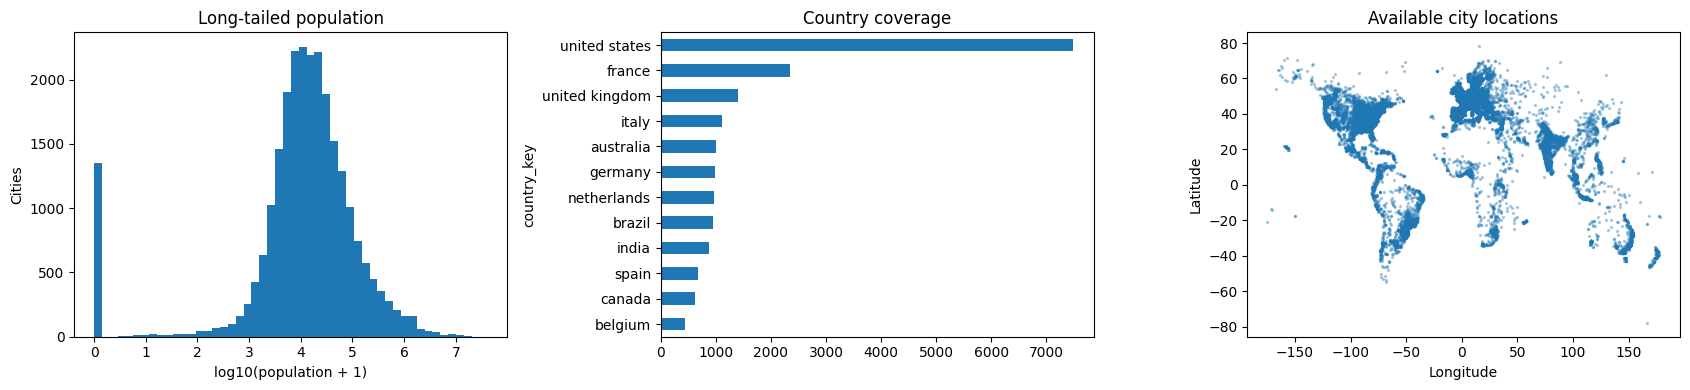

US cities: 7484 Traditional-label coverage: 0.9274452164617851


,cities
msa,
New York-Northern New Jersey-Long Island NY-NJ-PA MSA,526
Chicago-Naperville-Joliet IL-IN-WI MSA,200
Philadelphia-Camden-Wilmington PA-NJ-DE-MD MSA,195
Boston-Cambridge-Quincy MA-NH MSA,166
Los Angeles-Long Beach-Santa Ana CA MSA,157
Washington-Arlington-Alexandria DC-VA-MD-WV MSA,111
TX NONMETROPOLITAN AREA,101
Detroit-Warren-Livonia MI MSA,91
NC NONMETROPOLITAN AREA,90


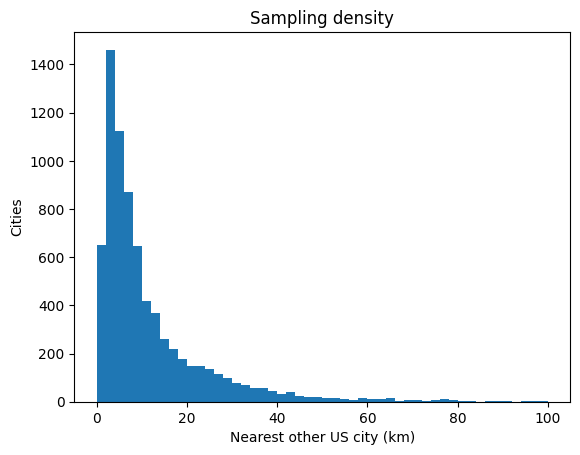

In [3]:
display(cleaner.rows[cleaner.required].isna().sum().to_frame('missing'))
display(cities.population.describe(percentiles=[.5,.9,.95,.99]).to_frame())
display(cities.country_key.value_counts().head(15).to_frame('cities'))
fig, ax = plt.subplots(1,3,figsize=(17,4))
ax[0].hist(np.log10(cities.population.dropna()+1), bins=50)
ax[0].set(xlabel='log10(population + 1)', ylabel='Cities', title='Long-tailed population')
cities.country_key.value_counts().head(12).sort_values().plot.barh(ax=ax[1], title='Country coverage')
g = cities[cities.geo_valid]
ax[2].scatter(g.longitude,g.latitude,s=2,alpha=.3)
ax[2].set(xlabel='Longitude',ylabel='Latitude',title='Available city locations')
plt.tight_layout(); plt.show()
us = cities[cities.geo_valid & cities.country_key.eq('united states')].copy()
traditional = us.msa.fillna('').str.strip()
print('US cities:', len(us), 'Traditional-label coverage:', traditional.ne('').mean())
display(traditional[traditional.ne('')].value_counts().head(12).to_frame('cities'))
features = cleaner.transform(us)
# Exclude self; geographic nearest-neighbor distance illustrates sampling density.
dist, _ = BallTree(features['radians'], metric='haversine').query(features['radians'], k=2)
plt.hist(dist[:,1]*EARTH_KM, bins=np.linspace(0,100,51))
plt.xlabel('Nearest other US city (km)'); plt.ylabel('Cities'); plt.title('Sampling density'); plt.show()


## 3. Processing API and model comparisons
K-means uses 3D Earth coordinates to avoid longitude wrap-around. Its inertia is in squared kilometers; it forces every city into a group and is a baseline. An elbow is a heuristic, not proof of an optimal number. Silhouette uses a reproducible sample.

DBSCAN uses haversine kilometers and can leave noise points. Ordinary city-count density depends on how cities were sampled, and connected chains can span long distances. The final model clusters only substantial population centers with DBSCAN, then partitions any long chain around deterministic, largest-first anchors. All cities must be within the catchment radius of their assigned anchor. Countries are modeled separately; this intentionally excludes cross-border metros.


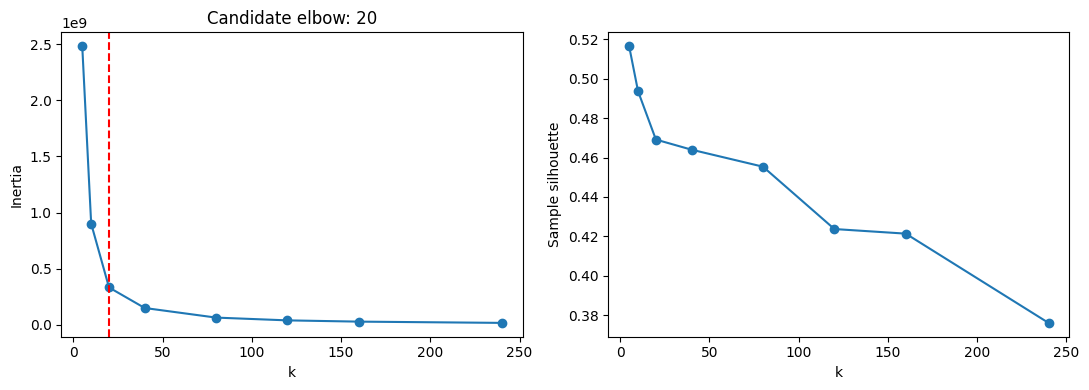

,k,inertia,silhouette
0,5,2.482157e+09,0.516527
1,10,9.017652e+08,0.493664
2,20,3.336283e+08,0.469114
3,40,1.508900e+08,0.463970
4,80,6.545186e+07,0.455347
5,120,4.067803e+07,0.423700
6,160,2.954977e+07,0.421362
7,240,1.834695e+07,0.376059


In [4]:
class DataProcessingAPI:
    def kmeans(self, d, k):
        x = DataCleaningAPI.transform(d)['xyz_km']
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(x)
        return model, model.labels_
    def dbscan(self, d, eps_km=25, min_samples=5):
        x = DataCleaningAPI.transform(d)['radians']
        return DBSCAN(eps=eps_km/EARTH_KM, min_samples=min_samples,
                      metric='haversine', algorithm='ball_tree').fit_predict(x)
    def metros(self, d, core_population=50000, seed_link_km=25, catchment_km=40):
        if core_population <= 0 or seed_link_km <= 0 or catchment_km <= 0:
            raise ValueError('Thresholds must be positive')
        out = d.copy()
        out['Your MSA'] = ['Review required | row ' + str(i) for i in out.row_id]
        out['anchor_distance_km'] = np.nan
        out['metro'] = False
        for country, group in out[out.geo_valid].groupby('country_key',sort=True):
            group = group.sort_values(['population','city_key','state_key','latitude','longitude'],
                                      ascending=[False,True,True,True,True],na_position='last')
            seeds = group[group.population.ge(core_population)].copy()
            anchors = []
            if len(seeds):
                seeds['component'] = self.dbscan(seeds,seed_link_km,1)
                for _, component in seeds.groupby('component',sort=True):
                    chosen = []
                    for idx, row in component.iterrows():
                        coord = np.radians([[row.latitude,row.longitude]])
                        if not chosen:
                            chosen.append(idx)
                        else:
                            tree = BallTree(np.radians(out.loc[chosen,['latitude','longitude']]),metric='haversine')
                            distance = tree.query(coord,k=1)[0][0,0]*EARTH_KM
                            if distance > catchment_km: chosen.append(idx)
                    anchors.extend(chosen)
            # Largest-first order also makes nearest-anchor ties deterministic.
            anchors = group.loc[anchors].sort_values(['population','city_key','state_key','latitude','longitude'],
                                                     ascending=[False,True,True,True,True])
            for idx,row in group.iterrows():
                out.at[idx,'Your MSA'] = f'Non-metro | {row.city} | {row.state} | {country} | entity {row.model_id}'
            if len(anchors):
                tree = BallTree(np.radians(anchors[['latitude','longitude']]),metric='haversine')
                distance, nearest = tree.query(np.radians(group[['latitude','longitude']]),k=1)
                distance = distance[:,0]*EARTH_KM
                for idx,km,j in zip(group.index,distance,nearest[:,0]):
                    if km <= catchment_km + 1e-9:
                        a = anchors.iloc[j]
                        out.at[idx,'Your MSA'] = f'{a.city} Metro | {a.state} | {country} | anchor {a.model_id}'
                        out.at[idx,'anchor_distance_km'] = km
                        out.at[idx,'metro'] = True
        return out

processor = DataProcessingAPI()
ks = [5,10,20,40,80,120,160,240]
km_rows = []
for k in ks:
    if k >= len(us): continue
    model, labels = processor.kmeans(us,k)
    assert np.isfinite(model.inertia_) and np.isfinite(model.cluster_centers_).all()
    score = silhouette_score(features['xyz_km'],labels,sample_size=min(1500,len(us)),random_state=SEED)
    km_rows.append({'k':k,'inertia':model.inertia_,'silhouette':score})
km_results = pd.DataFrame(km_rows)
# Max distance from the endpoint line in normalized k/inertia coordinates.
x = (km_results.k-km_results.k.min())/(km_results.k.max()-km_results.k.min())
y = (km_results.inertia-km_results.inertia.min())/(km_results.inertia.max()-km_results.inertia.min())
elbow_k = int(km_results.loc[np.argmax((1-x)-y),'k'])
fig,ax = plt.subplots(1,2,figsize=(11,4))
ax[0].plot(km_results.k,km_results.inertia,'o-'); ax[0].axvline(elbow_k,color='red',linestyle='--')
ax[0].set(xlabel='k',ylabel='Inertia',title=f'Candidate elbow: {elbow_k}')
ax[1].plot(km_results.k,km_results.silhouette,'o-'); ax[1].set(xlabel='k',ylabel='Sample silhouette')
plt.tight_layout(); plt.show(); display(km_results)


In [5]:
db_rows = []
for eps in [10,25,40,60]:
    for minimum in [3,5,10]:
        labels = processor.dbscan(us,eps,minimum)
        db_rows.append({'eps_km':eps,'min_samples':minimum,
                        'clusters':len(set(labels)-{-1}),'noise_fraction':float((labels==-1).mean())})
display(pd.DataFrame(db_rows))


,eps_km,min_samples,clusters,noise_fraction
0,10,3,306,0.470337
1,10,5,108,0.618920
2,10,10,29,0.803314
3,25,3,235,0.171833
4,25,5,142,0.255211
5,25,10,60,0.434928
6,40,3,120,0.066809
7,40,5,92,0.117317
8,40,10,64,0.228087
9,60,3,53,0.029530


### Optional SVM diagnostic
SVM is supervised. Here it predicts metro versus non-metro from the noisy traditional US labels, using coordinates and log population. It cannot create international MSA identities or validate the proposed model. A random split is an optimistic diagnostic because neighboring cities can appear in both sets; a spatial holdout would be required for deployment. Scaling and population imputation are fitted only on training data.

In [6]:
from sklearn.impute import SimpleImputer
labeled = us[us.msa.fillna('').str.strip().ne('')].copy()
y = (~labeled.msa.str.contains('NONMETROPOLITAN',case=False,na=False)).astype(int)
x = np.column_stack([DataCleaningAPI.transform(labeled)['xyz_km'], np.log1p(labeled.population)])
if y.nunique() == 2 and y.value_counts().min() >= 5:
    x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.25,stratify=y,random_state=SEED)
    svm = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                        SVC(C=1,kernel='rbf',class_weight='balanced'))
    svm.fit(x_train,y_train)
    print('SVM noisy-label balanced accuracy (optimistic random split):',
          round(balanced_accuracy_score(y_test,svm.predict(x_test)),3))
else:
    print('SVM skipped: insufficient examples in both classes.')


SVM noisy-label balanced accuracy (optimistic random split): 0.726


## 4. Final model and sensitivity
Default policy: an observed city of at least 50,000 people can seed a metro; seed links span 25 km; a city must be within 40 km of its anchor. These are interpretable assumptions, not learned optimal thresholds. No minimum cluster count is required. A sufficiently large isolated city can be a one-city metro. A small isolated city is retained individually. Missing population prevents seeding but does not prevent assignment.

Sensitivity reports how assignments change; choose parameters using practitioner requirements and commuting/travel data when available, rather than maximizing agreement with noisy labels.

In [7]:
sensitivity = []
base_us = processor.metros(us)
for core in [25000,50000,100000]:
    for radius in [25,40,60]:
        r = processor.metros(us,core_population=core,catchment_km=radius)
        sensitivity.append({'core_population':core,'radius_km':radius,
                            'metro_entities':r.loc[r.metro,'Your MSA'].nunique(),
                            'metro_city_fraction':r.metro.mean(),
                            'assignment_ARI_vs_default':adjusted_rand_score(base_us['Your MSA'],r['Your MSA'])})
display(pd.DataFrame(sensitivity))
result = processor.metros(cities)
country_summary = result.groupby('country_key').agg(cities=('model_id','size'),
                      metro_cities=('metro','sum'),entities=('Your MSA','nunique'))
display(country_summary.sort_values('cities',ascending=False).head(20))
metro_summary = result[result.metro].groupby('Your MSA').agg(cities=('model_id','size'),
    observed_population=('population',lambda s:s.sum(min_count=1)),max_anchor_km=('anchor_distance_km','max'))
display(metro_summary.sort_values('observed_population',ascending=False).head(20))
display(result[result.country_key.ne('united states')][['city','state','country','population','Your MSA']].head(20))


,core_population,radius_km,metro_entities,metro_city_fraction,assignment_ARI_vs_default
0,25000,25,666,0.658872,0.462632
1,25000,40,559,0.778728,0.825498
2,25000,60,509,0.883218,0.593966
3,50000,25,385,0.508151,0.529340
4,50000,40,331,0.643640,1.000000
5,50000,60,306,0.764832,0.607605
6,100000,25,200,0.351684,0.520715
7,100000,40,186,0.522849,0.783910
8,100000,60,178,0.652325,0.581154


,cities,metro_cities,entities
country_key,,,
united states,7484,4817,2998
france,2341,1820,595
united kingdom,1398,1270,183
italy,1114,911,264
australia,1006,718,316
germany,979,886,181
netherlands,965,936,46
brazil,952,705,510
india,868,787,531


,cities,observed_population,max_anchor_km
Your MSA,,,
sao paulo Metro | sao paulo | brazil | anchor 19042,3,41330035.0,32.205007
istanbul Metro | istanbul | turkey | anchor 18956,20,34824121.0,38.472213
shenzhen Metro | guangdong | china | anchor 19106,21,30590282.0,33.232433
shanghai Metro | shanghai | china | anchor 18768,2,27502674.0,7.763724
mexico city Metro | mexico city | mexico | anchor 19326,27,25947538.0,30.423023
guangzhou Metro | guangdong | china | anchor 18370,3,25349644.0,30.689858
new york city Metro | new york | united states | anchor 19166,153,23320593.0,39.919085
bangalore Metro | karnataka | india | anchor 20284,7,22337055.0,29.756335
beijing Metro | beijing | china | anchor 19495,1,18960744.0,0.000000


,city,state,country,population,Your MSA
3,sint anthonis,north brabant,netherlands,3340.0,nijmegen Metro | gelderland | netherlands | an...
4,machali,o higgins region,chile,27595.0,rancagua Metro | o higgins region | chile | an...
5,jankowice,silesia,poland,2840.0,bielsko biala Metro | silesia | poland | ancho...
7,fjerritslev,north denmark,denmark,3332.0,aalborg Metro | north denmark | denmark | anch...
8,palmanova,balearic islands,spain,7040.0,palma Metro | balearic islands | spain | ancho...
9,astorga,castille and leon,spain,12078.0,Non-metro | astorga | castille and leon | spai...
10,kilsyth,scotland,united kingdom,9860.0,glasgow Metro | scotland | united kingdom | an...
11,netstal,glarus,switzerland,2900.0,Non-metro | netstal | glarus | switzerland | e...
12,revesby,new south wales,australia,14056.0,sydney Metro | new south wales | australia | a...
14,flims,grisons,switzerland,2536.0,Non-metro | flims | grisons | switzerland | en...


## 5. Evaluation and geographic inspection
Agreement measures are descriptive, not ground-truth accuracy. Exclude traditional non-metro labels from cluster agreement: they can aggregate unrelated rural cities across a state. Report metro status separately.

ARI on traditionally metro-labeled cities: 0.3072767700922834
NMI on traditionally metro-labeled cities: 0.8053214083242666


Proposed metro,False,True
Traditional metro,,
False,1443,326
True,1140,4032


,city,state,population,msa,Your MSA
47,bloomfield,new mexico,7314.0,Farmington NM MSA,Non-metro | bloomfield | new mexico | united s...
71,warrensburg,new york,3103.0,Glens Falls NY MSA,Non-metro | warrensburg | new york | united st...
114,contoocook,new hampshire,1444.0,NH NONMETROPOLITAN AREA,manchester Metro | new hampshire | united stat...
119,valdese,north carolina,4459.0,Hickory-Lenoir-Morganton NC MSA,Non-metro | valdese | north carolina | united ...
121,tuscola,illinois,4443.0,IL NONMETROPOLITAN AREA,champaign Metro | illinois | united states | a...
129,middletown,virginia,1315.0,Washington-Arlington-Alexandria DC-VA-MD-WV MSA,Non-metro | middletown | virginia | united sta...
131,bushnell,florida,2995.0,FL NONMETROPOLITAN AREA,the villages Metro | florida | united states |...
143,roaring spring,pennsylvania,2537.0,Altoona PA MSA,Non-metro | roaring spring | pennsylvania | un...
145,holloman afb,new mexico,4096.0,Las Cruces NM MSA,Non-metro | holloman afb | new mexico | united...
171,jackson,minnesota,3234.0,Jackson MS MSA,Non-metro | jackson | minnesota | united state...


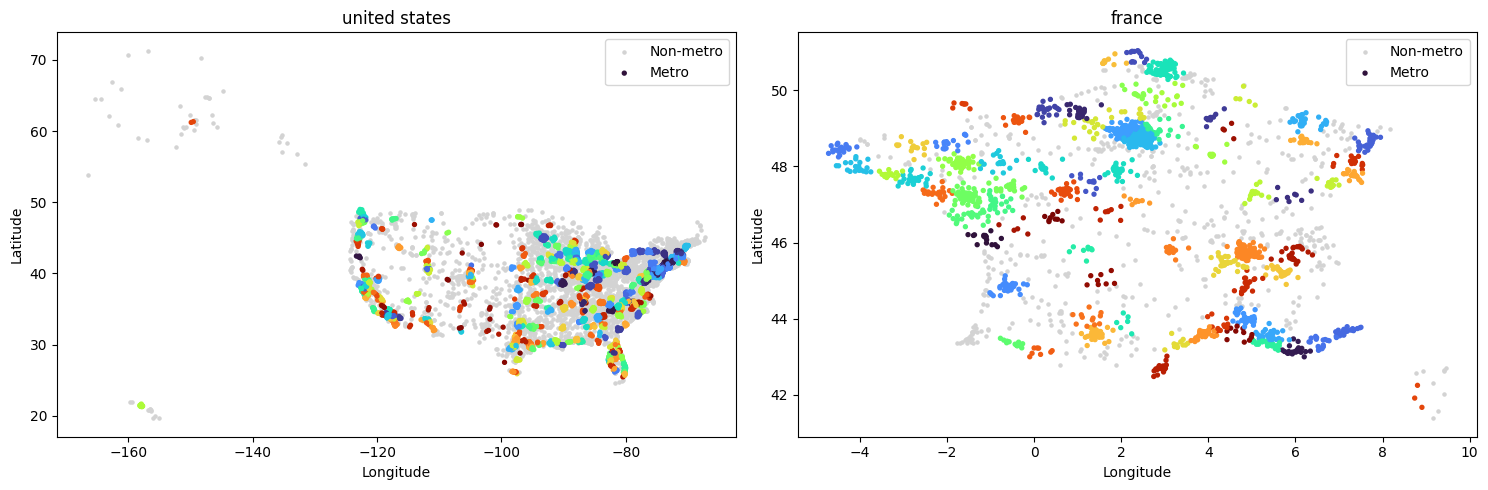

,city,population,msa,Your MSA
71,warrensburg,3103.0,Glens Falls NY MSA,Non-metro | warrensburg | new york | united st...
128,menands,3998.0,NaN,albany Metro | new york | united states | anch...
214,marcy,9465.0,Utica-Rome NY MSA,utica Metro | new york | united states | ancho...
217,sidney,3755.0,NY NONMETROPOLITAN AREA,Non-metro | sidney | new york | united states ...
221,new berlin,974.0,NY NONMETROPOLITAN AREA,Non-metro | new berlin | new york | united sta...
236,west henrietta,11691.0,Rochester NY MSA,rochester Metro | new york | united states | a...
286,watkins glen,1859.0,NY NONMETROPOLITAN AREA,Non-metro | watkins glen | new york | united s...
369,hamilton college,0.0,NaN,utica Metro | new york | united states | ancho...
472,alden,2589.0,Buffalo-Niagara Falls NY MSA,buffalo Metro | new york | united states | anc...
526,manlius,4630.0,Syracuse NY MSA,syracuse Metro | new york | united states | an...


In [8]:
u = result[result.country_key.eq('united states')].copy()
known = u.msa.fillna('').str.strip().ne('')
old_metro = ~u.msa.fillna('').str.contains('NONMETROPOLITAN',case=False)
mask = known & old_metro
if mask.sum() > 1:
    print('ARI on traditionally metro-labeled cities:',adjusted_rand_score(u.loc[mask,'msa'],u.loc[mask,'Your MSA']))
    print('NMI on traditionally metro-labeled cities:',normalized_mutual_info_score(u.loc[mask,'msa'],u.loc[mask,'Your MSA']))
display(pd.crosstab(old_metro[known],u.loc[known,'metro'],rownames=['Traditional metro'],colnames=['Proposed metro']))
display(u[known & (old_metro != u.metro)][['city','state','population','msa','Your MSA']].head(20))
fig,axes = plt.subplots(1,2,figsize=(15,5))
for ax,country in zip(axes,['united states',country_summary.drop(index='united states',errors='ignore').cities.idxmax()]):
    z = result[result.country_key.eq(country) & result.geo_valid]
    rural = z[~z.metro]; metro = z[z.metro]
    ax.scatter(rural.longitude,rural.latitude,s=5,c='lightgray',label='Non-metro')
    colors = pd.factorize(metro['Your MSA'])[0]
    ax.scatter(metro.longitude,metro.latitude,c=colors,cmap='turbo',s=8,label='Metro')
    ax.set(title=country,xlabel='Longitude',ylabel='Latitude'); ax.legend()
plt.tight_layout(); plt.show()
# Rural upstate NY is explicitly inspected rather than assumed to be correct.
display(u[u.state_key.eq('new york') & u.latitude.gt(42)][['city','population','msa','Your MSA']].head(30))


## 6. Export and verification
The primary export has exactly the requested seven columns. Country is encoded in the proposed label to avoid international name collisions; a separate diagnostics file retains country, row identity and assignment distance. Unknown numeric values remain blank. Invalid geography receives a review entity rather than a fabricated metro.


In [9]:
mapped = cleaner.rows.merge(result[['model_id','Your MSA','metro','anchor_distance_km']],
                            on='model_id',how='left',validate='many_to_one').sort_values('row_id')
final = mapped[['city','state','latitude','longitude','population','msa','Your MSA']].rename(columns={
    'city':'City','state':'State','latitude':'Latitude','longitude':'Longitude',
    'population':'Population','msa':'Traditional MSA'})
assert len(final) == len(cleaner.rows)
assert final['Your MSA'].notna().all()
assert result.loc[result.metro,'anchor_distance_km'].le(40+1e-9).all()
assert result.loc[~result.metro & result.geo_valid,'Your MSA'].nunique() == (~result.metro & result.geo_valid).sum()
# Synthetic checks: nearby satellite joins; distant rural city stays separate;
# a cross-border city cannot join the neighboring country's anchor.
toy = pd.DataFrame({'city':['Core','Satellite','Rural','Border'], 'state':['s']*4,
    'country':['a','a','a','b'], 'latitude':[0,0,0,0], 'longitude':[0,.1,2,.1],
    'population':[100000,1000,1000,1000], 'msa':[None]*4})
toy.to_csv('synthetic_check.csv',index=False)
tc = DataCleaningAPI(); tr = processor.metros(tc.clean('synthetic_check.csv'))
assert tr.metro.tolist() == [True,True,False,False]
assert tr['Your MSA'].iloc[0] == tr['Your MSA'].iloc[1]
Path('synthetic_check.csv').unlink()
final.to_csv(OUTPUT,index=False)
mapped.to_csv('msa_diagnostics.csv',index=False)
country_summary.to_csv('country_summary.csv')
print('Saved:',OUTPUT.resolve(), 'Rows:',len(final))
print('Unique metro entities:',result.loc[result.metro,'Your MSA'].nunique())
print('Non-metro entities:',int((~result.metro & result.geo_valid).sum()))
display(final.head(12))


Saved: /Users/garimajain/Documents/Codex/2026-10-12/help/outputs/msa_output.csv Rows: 25410
Unique metro entities: 3550
Non-metro entities: 6229


,City,State,Latitude,Longitude,Population,Traditional MSA,Your MSA
0,mahopac,new york,41.37232,-73.73346,8369.0,New York-Northern New Jersey-Long Island NY-NJ...,danbury Metro | connecticut | united states | ...
1,seven hills,ohio,41.39533,-81.67624,11690.0,NaN,cleveland Metro | ohio | united states | ancho...
2,new martinsville,west virginia,39.64452,-80.85760,5218.0,WV NONMETROPOLITAN AREA,Non-metro | new martinsville | west virginia |...
3,sint anthonis,north brabant,51.62667,5.88194,3340.0,NaN,nijmegen Metro | gelderland | netherlands | an...
4,machali,o higgins region,-34.18082,-70.64933,27595.0,NaN,rancagua Metro | o higgins region | chile | an...
5,jankowice,silesia,50.00090,18.98901,2840.0,NaN,bielsko biala Metro | silesia | poland | ancho...
6,jacksonville,oregon,42.31346,-122.96699,2883.0,Jacksonville FL MSA,medford Metro | oregon | united states | ancho...
7,fjerritslev,north denmark,57.08822,9.26622,3332.0,NaN,aalborg Metro | north denmark | denmark | anch...
8,palmanova,balearic islands,39.52470,2.53922,7040.0,NaN,palma Metro | balearic islands | spain | ancho...
9,astorga,castille and leon,42.45879,-6.05601,12078.0,NaN,Non-metro | astorga | castille and leon | spai...


## Interpretation, limitations and next steps
This approach offers a repeatable international definition, explicit rural entities and bounded distance from a population anchor. These properties may be useful for initial site selection and geographic reach analyses. They do **not** establish superiority over official US MSAs, whose labor-market integration cannot be recovered from this CSV alone.

City-level population depends on administrative boundaries; dense chains, islands, mountains, travel times, cross-border workers, uneven coverage and small economic hubs all warrant review. Default radii can wrongly include rural towns near a core or miss commuter towns farther away. The model rebuilds anchors on each run, so IDs are stable for this fixed input but are not a versioned registry. Fit national/regional policy thresholds using commuting or workforce data, validate on held-out regions, and add travel-time constraints before operational use.

**References:** [scikit-learn DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html), [clustering guide](https://scikit-learn.org/stable/modules/clustering.html), [SVM guide](https://scikit-learn.org/stable/modules/svm.html).


Official MSA delineation uses urban areas, counties and commuting ties, rather than a city-point distance radius: [US Census glossary](https://www.census.gov/programs-surveys/metro-micro/about/glossary.html). Our 50,000-person city threshold is a modeling policy, not the official urban-area test. Zero population estimates are retained as supplied; they may encode unknown values and cannot seed a metro.

## Results from the supplied file
The executed notebook preserves **25,410 input rows**, producing **3,550 metro entities** and **6,229 non-metro entities**. Among 7,484 US cities, 4,817 receive a metro assignment. On traditional metro-labeled US cities, ARI is approximately **0.307** and NMI **0.805**; these quantify similarity, not correctness. The supervised SVM diagnostic achieves balanced accuracy **0.726** on its optimistic random holdout.

A useful noisy-label example is **Jacksonville, Oregon**: its supplied traditional label refers to Jacksonville, Florida, whereas the geographic model assigns it to nearby **Medford, Oregon**. This illustrates a specific correction supported by geography. It does not prove that all disagreements are improvements. Inspect the exported diagnostics and parameter sensitivity before choosing the final policy.

Validation passed: seven-column schema, all input rows retained, complete proposed labels, maximum 40 km anchor distance, separate non-metro identities, and synthetic satellite/rural/cross-border cases. The notebook was executed from top to bottom without errors or numerical warnings using the pinned numerical packages.
